In [ ]:
import os
import cv2
import numpy as np
import pandas as pd

def generate_bbox(img_path, img_size=224):
    img = cv2.imread(img_path)
    if img is None:
        return 0, 0, img_size, img_size  # fallback: seluruh gambar
    
    img_resized = cv2.resize(img, (img_size, img_size))
    gray = cv2.cvtColor(img_resized, cv2.COLOR_BGR2GRAY)
    
    # Otsu thresholding untuk pisahkan subjek dari background
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    
    # Cari kontur terbesar (= objek utama)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    
    if not contours:
        return 0, 0, img_size, img_size
    
    largest = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(largest)
    
    # Normalisasi ke [0, 1]
    x_min = x / img_size
    y_min = y / img_size
    x_max = (x + w) / img_size
    y_max = (y + h) / img_size
    
    return x_min, y_min, x_max, y_max

# Build dataframe dengan bbox
TRAIN_DIR = "/kaggle/input/datasets/phucthaiv02/butterfly-image-classification/train"
CSV_PATH  = "/kaggle/input/datasets/phucthaiv02/butterfly-image-classification/Training_set.csv"

df = pd.read_csv(CSV_PATH)
bboxes = []

for fname in df["filename"]:
    path = os.path.join(TRAIN_DIR, fname)
    bbox = generate_bbox(path)
    bboxes.append(bbox)

df[["x_min","y_min","x_max","y_max"]] = pd.DataFrame(bboxes, index=df.index)
print(df.head())

      filename                     label  x_min  y_min     x_max     y_max
0  Image_1.jpg          SOUTHERN DOGFACE    0.0    0.0  0.919643  0.977679
1  Image_2.jpg                    ADONIS    0.0    0.0  0.991071  1.000000
2  Image_3.jpg            BROWN SIPROETA    0.0    0.0  1.000000  1.000000
3  Image_4.jpg                   MONARCH    0.0    0.0  1.000000  1.000000
4  Image_5.jpg  GREEN CELLED CATTLEHEART    0.0    0.0  1.000000  1.000000


In [2]:
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder
import numpy as np

IMG_SIZE   = 224
BATCH_SIZE = 32

# Encode label
le = LabelEncoder()
df["label_enc"] = le.fit_transform(df["label"])
NUM_CLASSES = len(le.classes_)

class ButterflyDetectionDataset(tf.keras.utils.Sequence):
    def __init__(self, df, img_dir, batch_size=32, img_size=224, shuffle=True):
        self.df         = df.reset_index(drop=True)
        self.img_dir    = img_dir
        self.batch_size = batch_size
        self.img_size   = img_size
        self.shuffle    = shuffle
        self.indices    = np.arange(len(self.df))
        if shuffle:
            np.random.shuffle(self.indices)

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        images, labels, bboxes = [], [], []

        for i in batch_idx:
            row  = self.df.iloc[i]
            path = os.path.join(self.img_dir, row["filename"])

            img = tf.keras.preprocessing.image.load_img(path, target_size=(self.img_size, self.img_size))
            img = tf.keras.preprocessing.image.img_to_array(img) / 255.0

            images.append(img)
            labels.append(to_categorical(row["label_enc"], NUM_CLASSES))
            bboxes.append([row["x_min"], row["y_min"], row["x_max"], row["y_max"]])

        return (
            np.array(images),
            {
                "cls_output":  np.array(labels),
                "bbox_output": np.array(bboxes, dtype=np.float32)
            }
        )

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

# Split train/val
from sklearn.model_selection import train_test_split
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df["label_enc"], random_state=42)

train_gen = ButterflyDetectionDataset(train_df, TRAIN_DIR)
val_gen   = ButterflyDetectionDataset(val_df,   TRAIN_DIR, shuffle=False)

2026-03-31 09:22:28.136381: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1774948948.335634      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1774948948.399399      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1774948948.907096      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774948948.907135      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1774948948.907137      55 computation_placer.cc:177] computation placer alr

In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import ResNet50

def build_detection_model(num_classes, img_size=224, pretrained_model_path=None):
    inputs  = layers.Input(shape=(img_size, img_size, 3))
    backbone = ResNet50(include_top=False, weights="imagenet", input_tensor=inputs)
    
    # Jika ada model tersimpan, load bobot backbone-nya
    if pretrained_model_path and os.path.exists(pretrained_model_path):
        pretrained = tf.keras.models.load_model(pretrained_model_path)
        # Copy bobot layer yang namanya sama
        for layer in backbone.layers:
            try:
                layer.set_weights(pretrained.get_layer(layer.name).get_weights())
            except (ValueError, KeyError):
                pass
        print("Bobot backbone dari tugas 1 berhasil di-load!")

    # Freeze backbone (train hanya head)
    backbone.trainable = False

    # Shared feature extractor
    x = backbone.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation="relu")(x)
    x = layers.Dropout(0.3)(x)

    # Head 1: Classification
    cls_out  = layers.Dense(num_classes, activation="softmax", name="cls_output")(x)

    # Head 2: Bounding Box (4 nilai: x_min, y_min, x_max, y_max)
    bbox_out = layers.Dense(128, activation="relu")(x)
    bbox_out = layers.Dense(4, activation="sigmoid", name="bbox_output")(bbox_out)

    model = Model(inputs=inputs, outputs=[cls_out, bbox_out])
    return model

model = build_detection_model(
    num_classes=NUM_CLASSES,
    pretrained_model_path="/kaggle/input/models/apasijann/modelresnet50/keras/default/1/butterfly_resnet50.keras"  # sesuaikan path
)
model.summary()

I0000 00:00:1774948974.892567      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1774948974.898923      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
Bobot backbone dari tugas 1 berhasil di-load!


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,741,455 (94.38 MB)

 Trainable params: 1,153,743 (4.40 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss={
        "cls_output":  "categorical_crossentropy",
        "bbox_output": "mse"                       
    },
    loss_weights={
        "cls_output":  1.0,   
        "bbox_output": 5.0    
    },
    metrics={
        "cls_output":  "accuracy",
        "bbox_output": "mae"  
    }
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "butterfly_detection_best.keras",
        monitor="val_cls_output_accuracy",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        verbose=1
    )
]

history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=30,
    callbacks=callbacks
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30


I0000 00:00:1774948992.173510     125 service.cc:152] XLA service 0x7b8e60014c40 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1774948992.173564     125 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1774948992.173569     125 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1774948994.168079     125 cuda_dnn.cc:529] Loaded cuDNN version 91002


  1/163 ━━━━━━━━━━━━━━━━━━━━ 40:33 15s/step - bbox_output_loss: 0.2294 - bbox_output_mae: 0.4284 - cls_output_accuracy: 0.0625 - cls_output_loss: 4.6325 - loss: 5.7795

I0000 00:00:1774948999.785392     125 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step - bbox_output_loss: 0.0665 - bbox_output_mae: 0.1953 - cls_output_accuracy: 0.0151 - cls_output_loss: 4.5087 - loss: 4.8411
Epoch 1: val_cls_output_accuracy improved from -inf to 0.04923, saving model to butterfly_detection_best.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 45s 187ms/step - bbox_output_loss: 0.0663 - bbox_output_mae: 0.1949 - cls_output_accuracy: 0.0151 - cls_output_loss: 4.5081 - loss: 4.8396 - val_bbox_output_loss: 0.0271 - val_bbox_output_mae: 0.1156 - val_cls_output_accuracy: 0.0492 - val_cls_output_loss: 4.2251 - val_loss: 4.3590 - learning_rate: 1.0000e-04
Epoch 2/30
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - bbox_output_loss: 0.0258 - bbox_output_mae: 0.1150 - cls_output_accuracy: 0.0327 - cls_output_loss: 4.2621 - loss: 4.3913
Epoch 2: val_cls_output_accuracy improved from 0.04923 to 0.05308, saving model to butterfly_detection_best.keras
163/163 ━━━━━━━━━━━━━━━━━━━━ 17s 106ms/step - bbox_output_loss: 0.0258 - bbox_output_mae: 0

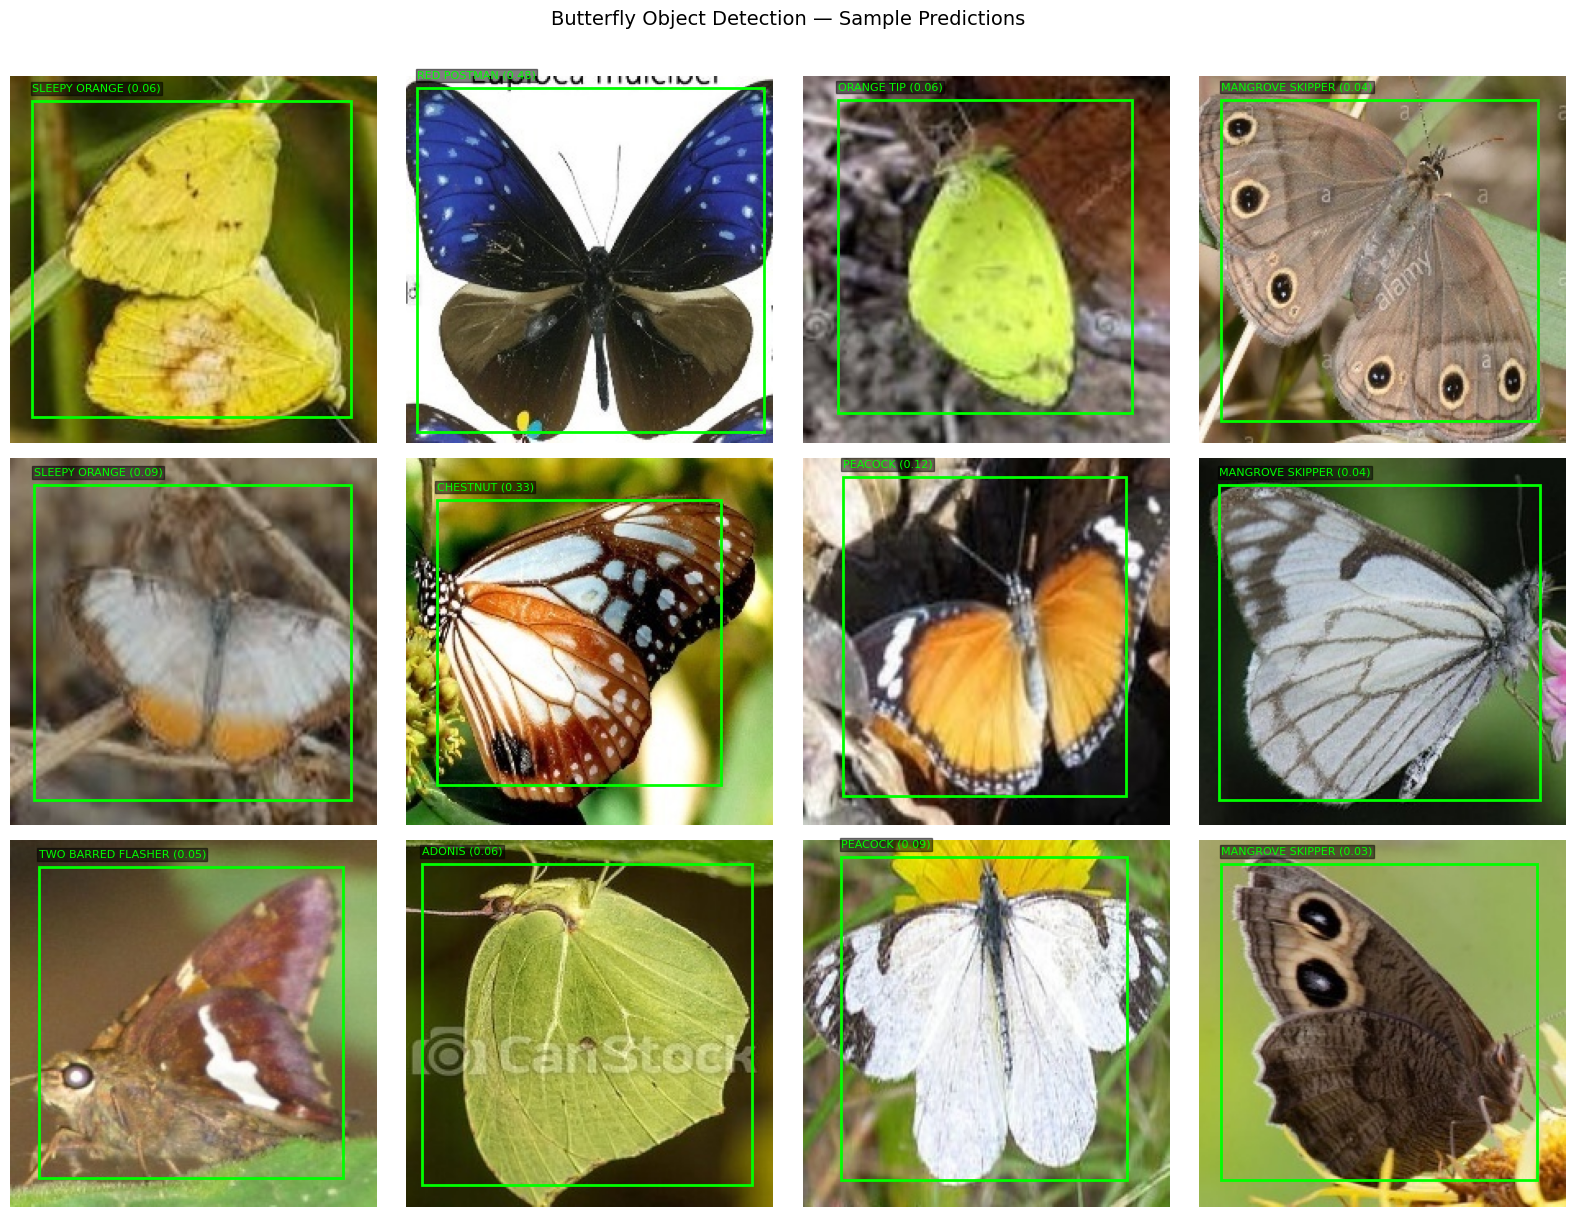

In [ ]:
def predict_grid(model, df, img_dir, label_encoder, n_samples=12, img_size=224, ncols=4):
    samples = df.sample(n=n_samples, random_state=42).reset_index(drop=True)
    nrows   = int(np.ceil(n_samples / ncols))
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 4))
    axes = axes.flatten()

    for i, row in samples.iterrows():
        path     = os.path.join(img_dir, row["filename"])
        img_orig = tf.keras.preprocessing.image.load_img(path, target_size=(img_size, img_size))
        img_arr  = tf.keras.preprocessing.image.img_to_array(img_orig) / 255.0
        img_input = np.expand_dims(img_arr, axis=0)

        cls_pred, bbox_pred = model.predict(img_input, verbose=0)

        label      = label_encoder.classes_[np.argmax(cls_pred[0])]
        confidence = np.max(cls_pred[0])
        x_min, y_min, x_max, y_max = bbox_pred[0]

        x_min_px = int(x_min * img_size)
        y_min_px = int(y_min * img_size)
        x_max_px = int(x_max * img_size)
        y_max_px = int(y_max * img_size)

        ax = axes[i]
        ax.imshow(img_arr)
        rect = patches.Rectangle(
            (x_min_px, y_min_px),
            x_max_px - x_min_px,
            y_max_px - y_min_px,
            linewidth=2, edgecolor="lime", facecolor="none"
        )
        ax.add_patch(rect)
        ax.text(
            x_min_px, y_min_px - 6,
            f"{label} ({confidence:.2f})",
            color="lime", fontsize=8,
            bbox=dict(facecolor="black", alpha=0.5, pad=1)
        )
        ax.axis("off")

    for j in range(i + 1, len(axes)):
        axes[j].axis("off")

    plt.suptitle("Butterfly Object Detection — Sample Predictions", fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig("detection_grid.png", dpi=150, bbox_inches="tight")
    plt.show()

predict_grid(model, val_df, TRAIN_DIR, le, n_samples=12, ncols=4)

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import seaborn as sns
import itertools
from sklearn.metrics import classification_report, confusion_matrix

all_cls_true, all_cls_pred, all_cls_conf = [], [], []
all_bbox_true, all_bbox_pred = [], []

for i in range(len(val_gen)):
    X, y = val_gen[i]
    cls_pred, bbox_pred = model.predict(X, verbose=0)

    all_cls_true.extend(np.argmax(y["cls_output"], axis=1))
    all_cls_pred.extend(np.argmax(cls_pred, axis=1))
    all_cls_conf.extend(np.max(cls_pred, axis=1))
    all_bbox_true.extend(y["bbox_output"])
    all_bbox_pred.extend(bbox_pred)

cls_true  = np.array(all_cls_true)
cls_pred  = np.array(all_cls_pred)
cls_conf  = np.array(all_cls_conf)
bbox_true = np.array(all_bbox_true)
bbox_pred = np.array(all_bbox_pred)
class_names = le.classes_

print(f"Total sampel validasi : {len(cls_true)}")
print(f"Jumlah kelas          : {len(class_names)}")
print(f"Overall accuracy      : {(cls_true == cls_pred).mean():.4f}")

Total sampel validasi : 1300
Jumlah kelas          : 75
Overall accuracy      : 0.2485


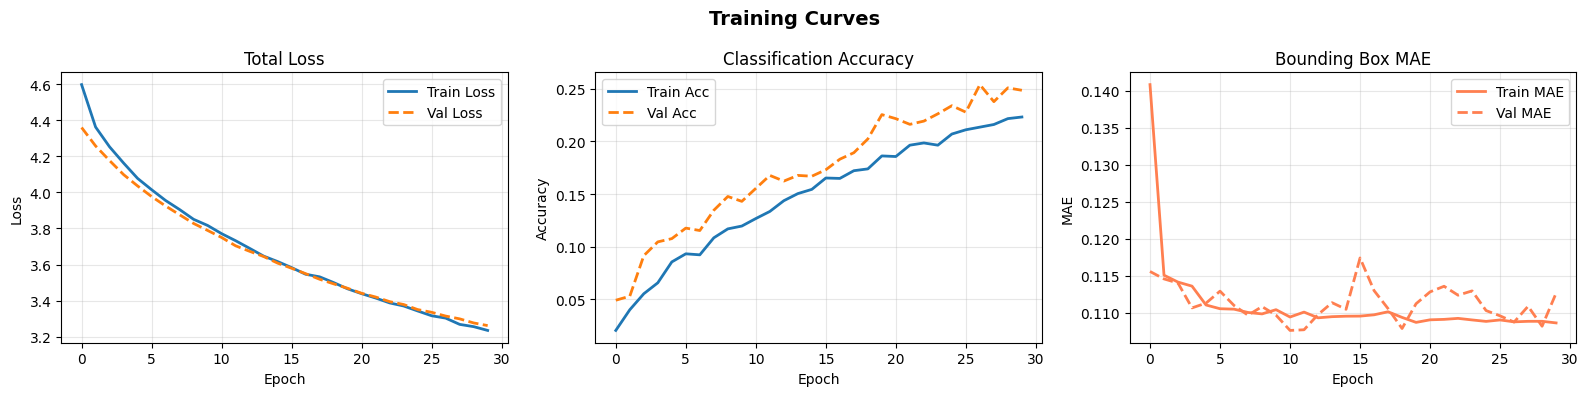

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Training Curves", fontsize=14, fontweight="bold")

# Total loss
axes[0].plot(history.history["loss"],     label="Train Loss", linewidth=2)
axes[0].plot(history.history["val_loss"], label="Val Loss",   linewidth=2, linestyle="--")
axes[0].set_title("Total Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Classification accuracy
axes[1].plot(history.history["cls_output_accuracy"],     label="Train Acc", linewidth=2)
axes[1].plot(history.history["val_cls_output_accuracy"], label="Val Acc",   linewidth=2, linestyle="--")
axes[1].set_title("Classification Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

# BBox MAE
axes[2].plot(history.history["bbox_output_mae"],     label="Train MAE", linewidth=2, color="coral")
axes[2].plot(history.history["val_bbox_output_mae"], label="Val MAE",   linewidth=2, color="coral", linestyle="--")
axes[2].set_title("Bounding Box MAE")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("MAE")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("plot_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

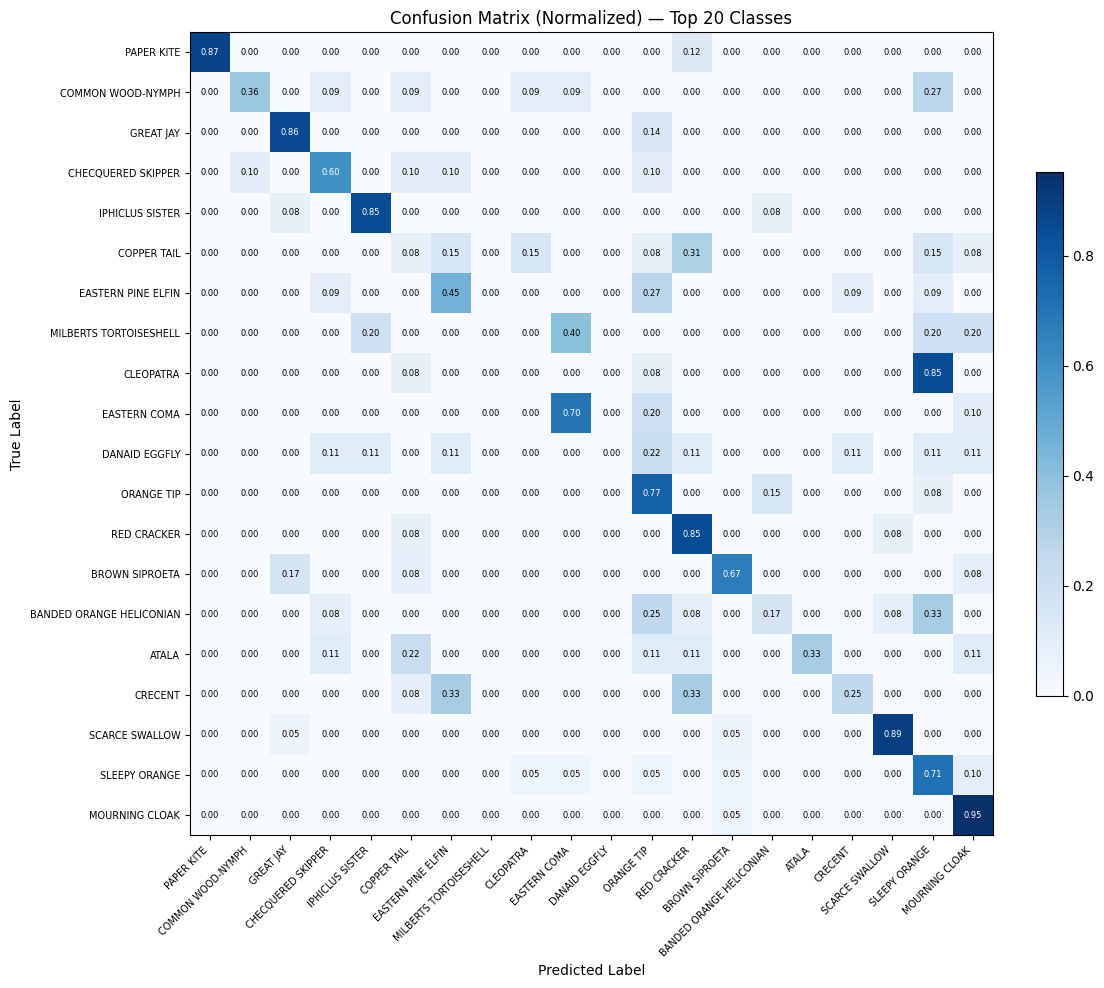

In [12]:
MAX_CLASSES = 20

# Ambil top kelas yang paling banyak muncul
top_indices = np.argsort(np.bincount(cls_true))[-MAX_CLASSES:]
mask        = np.isin(cls_true, top_indices)
cls_true_f  = cls_true[mask]
cls_pred_f  = cls_pred[mask]
names_f     = class_names[top_indices]

# Remap indeks ke 0..N
remap      = {old: new for new, old in enumerate(top_indices)}
cls_true_f = np.array([remap[v] for v in cls_true_f])
cls_pred_f = np.array([remap.get(v, -1) for v in cls_pred_f])
valid      = cls_pred_f >= 0
cls_true_f, cls_pred_f = cls_true_f[valid], cls_pred_f[valid]

cm = confusion_matrix(cls_true_f, cls_pred_f).astype(float)
cm = cm / (cm.sum(axis=1, keepdims=True) + 1e-8)  # normalize

n = len(names_f)
fig, ax = plt.subplots(figsize=(max(10, n * 0.55), max(8, n * 0.5)))
im = ax.imshow(cm, interpolation="nearest", cmap="Blues")
plt.colorbar(im, ax=ax, fraction=0.03)

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(names_f, rotation=45, ha="right", fontsize=7)
ax.set_yticklabels(names_f, fontsize=7)
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_title(f"Confusion Matrix (Normalized) — Top {n} Classes")

thresh = cm.max() / 2
for i, j in itertools.product(range(n), range(n)):
    ax.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center",
            color="white" if cm[i, j] > thresh else "black", fontsize=6)

plt.tight_layout()
plt.savefig("plot_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

/tmp/ipykernel_55/4251849700.py:33: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(coord_err, labels=coord_names, patch_artist=True,


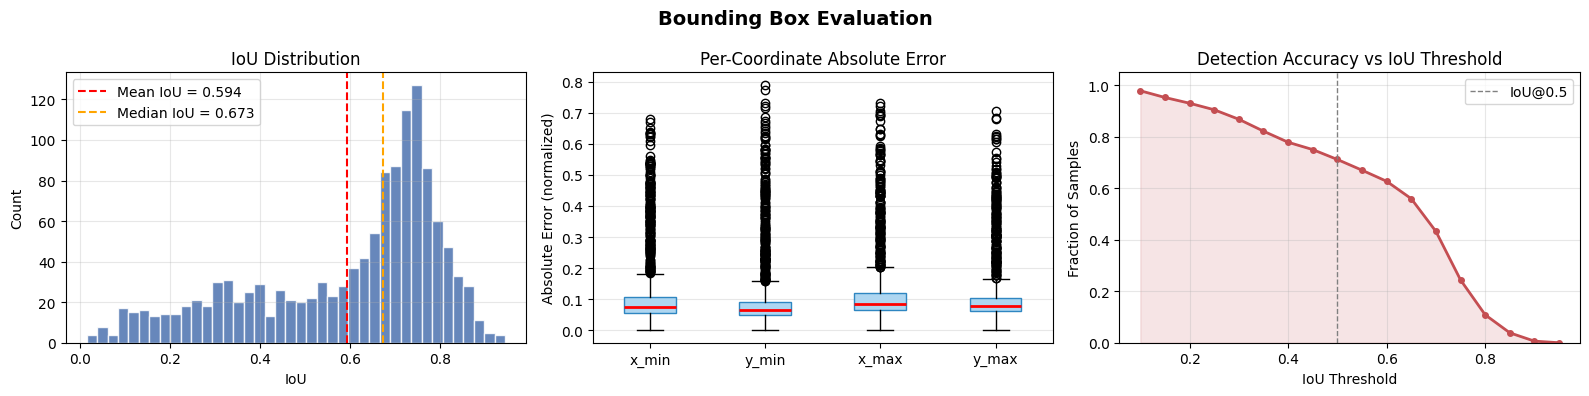

Mean IoU    : 0.5937
Median IoU  : 0.6729
IoU >= 0.50 : 71.2%
IoU >= 0.75 : 24.4%
Overall MAE : 0.1127


In [13]:
def compute_iou(box_true, box_pred):
    x1 = np.maximum(box_true[:, 0], box_pred[:, 0])
    y1 = np.maximum(box_true[:, 1], box_pred[:, 1])
    x2 = np.minimum(box_true[:, 2], box_pred[:, 2])
    y2 = np.minimum(box_true[:, 3], box_pred[:, 3])

    inter  = np.maximum(0, x2 - x1) * np.maximum(0, y2 - y1)
    area_t = (box_true[:, 2] - box_true[:, 0]) * (box_true[:, 3] - box_true[:, 1])
    area_p = (box_pred[:, 2] - box_pred[:, 0]) * (box_pred[:, 3] - box_pred[:, 1])
    union  = area_t + area_p - inter + 1e-8
    return inter / union

iou_scores  = compute_iou(bbox_true, bbox_pred)
coord_err   = np.abs(bbox_true - bbox_pred)
coord_names = ["x_min", "y_min", "x_max", "y_max"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Bounding Box Evaluation", fontsize=14, fontweight="bold")

# IoU distribution
axes[0].hist(iou_scores, bins=40, color="#4C72B0", edgecolor="white", alpha=0.85)
axes[0].axvline(iou_scores.mean(),     color="red",    linestyle="--", linewidth=1.5,
                label=f"Mean IoU = {iou_scores.mean():.3f}")
axes[0].axvline(np.median(iou_scores), color="orange", linestyle="--", linewidth=1.5,
                label=f"Median IoU = {np.median(iou_scores):.3f}")
axes[0].set_title("IoU Distribution")
axes[0].set_xlabel("IoU")
axes[0].set_ylabel("Count")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Per-coordinate error boxplot
axes[1].boxplot(coord_err, labels=coord_names, patch_artist=True,
                boxprops=dict(facecolor="#AED6F1", color="#2E86C1"),
                medianprops=dict(color="red", linewidth=2))
axes[1].set_title("Per-Coordinate Absolute Error")
axes[1].set_ylabel("Absolute Error (normalized)")
axes[1].grid(axis="y", alpha=0.3)

# Detection accuracy vs IoU threshold
thresholds = np.arange(0.1, 1.0, 0.05)
accuracies = [(iou_scores >= t).mean() for t in thresholds]
axes[2].plot(thresholds, accuracies, marker="o", linewidth=2,
             color="#C44E52", markersize=4)
axes[2].axvline(0.5, color="gray", linestyle="--", linewidth=1, label="IoU@0.5")
axes[2].fill_between(thresholds, accuracies, alpha=0.15, color="#C44E52")
axes[2].set_title("Detection Accuracy vs IoU Threshold")
axes[2].set_xlabel("IoU Threshold")
axes[2].set_ylabel("Fraction of Samples")
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig("plot_bbox_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Mean IoU    : {iou_scores.mean():.4f}")
print(f"Median IoU  : {np.median(iou_scores):.4f}")
print(f"IoU >= 0.50 : {(iou_scores >= 0.5).mean() * 100:.1f}%")
print(f"IoU >= 0.75 : {(iou_scores >= 0.75).mean() * 100:.1f}%")
print(f"Overall MAE : {coord_err.mean():.4f}")

In [ ]:
import os
import json
from datetime import datetime

SAVE_DIR = "/kaggle/working/butterfly_detection_model"
os.makedirs(SAVE_DIR, exist_ok=True)

#  1. Simpan full model 
model_path = os.path.join(SAVE_DIR, "butterfly_detection.keras")
model.save(model_path)
print(f"✓ Full model    : {model_path}")

#  2. Simpan bobot 
weights_path = os.path.join(SAVE_DIR, "butterfly_detection.weights.h5")
model.save_weights(weights_path)
print(f"✓ Weights only  : {weights_path}")

#  3. Simpan label encoder 
labels_path = os.path.join(SAVE_DIR, "class_names.json")
with open(labels_path, "w") as f:
    json.dump(le.classes_.tolist(), f, indent=2)
print(f"✓ Class names   : {labels_path}")

#  4. Simpan metadata training 
final_val_acc = max(history.history["val_cls_output_accuracy"])
final_val_mae = min(history.history["val_bbox_output_mae"])

metadata = {
    "saved_at":           datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "num_classes":        int(NUM_CLASSES),
    "image_size":         IMG_SIZE,
    "epochs_trained":     len(history.history["loss"]),
    "best_val_accuracy":  round(float(final_val_acc), 4),
    "best_val_bbox_mae":  round(float(final_val_mae), 4),
    "backbone":           "ResNet50",
    "input_shape":        [IMG_SIZE, IMG_SIZE, 3],
    "outputs": {
        "cls_output":  f"{NUM_CLASSES} classes (softmax)",
        "bbox_output": "4 coords normalized [x_min, y_min, x_max, y_max] (sigmoid)"
    }
}

meta_path = os.path.join(SAVE_DIR, "metadata.json")
with open(meta_path, "w") as f:
    json.dump(metadata, f, indent=2)
print(f"✓ Metadata      : {meta_path}")

# 5. Ringkasan
print("\n=== Model Saved ===")
for fname in sorted(os.listdir(SAVE_DIR)):
    fpath = os.path.join(SAVE_DIR, fname)
    size  = os.path.getsize(fpath) / (1024 * 1024)
    print(f"  {fname:<45} {size:.2f} MB")

print(f"\nBest val accuracy : {final_val_acc:.4f}")
print(f"Best val bbox MAE : {final_val_mae:.4f}")

✓ Full model    : /kaggle/working/butterfly_detection_model/butterfly_detection.keras
✓ Weights only  : /kaggle/working/butterfly_detection_model/butterfly_detection.weights.h5
✓ Class names   : /kaggle/working/butterfly_detection_model/class_names.json
✓ Metadata      : /kaggle/working/butterfly_detection_model/metadata.json

=== Model Saved ===
  butterfly_detection.keras                     103.82 MB
  butterfly_detection.weights.h5                103.66 MB
  class_names.json                              0.00 MB
  metadata.json                                 0.00 MB

Best val accuracy : 0.2538
Best val bbox MAE : 0.1076
